# Laptop Price Prediction Using Machine Learning

**Student:** BHOLA SANKAR MAJHI  
**Date:** 18 October 2026  
**Technology:** Python and Google Colab (Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn)  
**Dataset:** Laptop Price Dataset (`laptop_price.csv`)  
**Source:** [Kaggle – Laptop Price Dataset](https://www.kaggle.com/datasets/muhammetvarl/laptop-price)

---

## 1. Introduction

A laptop's price depends on many things: the brand, processor, RAM, storage, graphics card, screen size and laptop type. This project studies how these specifications relate to price, first through exploratory data analysis (EDA) and then through machine learning.

Two kinds of task are covered, and it helps to keep them apart:

- **Regression** predicts a numerical price in euros.
- **Classification** predicts a price *category* (Low, Medium or High) rather than an exact price. Logistic Regression is used for this.

## 2. Dataset Information

| Item | Detail |
|---|---|
| Dataset | Laptop Price Dataset (Kaggle) |
| File | `laptop_price.csv` |
| Records | 1,303 |
| Columns | 13 |
| Regression target | `Price_euros` |
| Classification target | Price category: Low, Medium, High |

### Dataset features

| Feature | Description |
|---|---|
| `laptop_ID` | Unique laptop identifier |
| `Company` | Laptop manufacturer |
| `Product` | Laptop model name |
| `TypeName` | Laptop category (for example Notebook or Gaming) |
| `Inches` | Screen size |
| `ScreenResolution` | Display resolution |
| `Cpu` | Processor information |
| `Ram` | Installed RAM |
| `Memory` | Storage configuration |
| `Gpu` | Graphics processing unit |
| `OpSys` | Operating system |
| `Weight` | Laptop weight |
| `Price_euros` | Laptop price in euros |

## 3. Project Objectives

1. Understand and clean the dataset.
2. Carry out exploratory data analysis (EDA).
3. Study how laptop specifications relate to price.
4. Build a Linear Regression model for price prediction.
5. Train and compare Random Forest and Gradient Boosting regressors.
6. Evaluate the regression models with MAE, RMSE and R².
7. Use Logistic Regression to classify laptops into price categories.
8. Evaluate the classifier with accuracy, precision, recall, F1-score, and ROC-AUC (a confusion matrix is also shown, for the Gradient Boosting predictions grouped into categories).
9. Select suitable models based on the results.
10. Identify limitations and possible future improvements.

## 4. Machine Learning Algorithms

**Regression models** (predict a numerical price): Linear Regression, Random Forest Regressor and Gradient Boosting Regressor.

**Classification model** (predicts a price category): Logistic Regression.

The price categories are:

- **Low:** Price ≤ €700
- **Medium:** €700 < Price ≤ €1500
- **High:** Price > €1500

## 5. Project Workflow

1. Dataset loading and inspection
2. Data quality check and cleaning
3. Exploratory data analysis and visualisation
4. Regression model development (Gradient Boosting, Random Forest, Linear Regression)
5. Regression model evaluation and comparison
6. Logistic Regression classification
7. ROC curve and ROC-AUC analysis
8. Interpretation, model selection, limitations and conclusion

## 6. Tools and Libraries

- **Python** and **Google Colab** – programming language and development environment
- **Pandas** and **NumPy** – data handling and numerical work
- **Matplotlib** and **Seaborn** – visualisation
- **Scikit-learn** – preprocessing pipelines, models and evaluation metrics

## 7. Project Scope

This project analyses the supplied laptop dataset and builds models from the features it contains. Predicted prices are estimates based on this historical data. They are not guaranteed current market prices.


# Step 1: Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Dataset Understanding

In [ ]:
df = pd.read_csv("/content/laptop_price.csv", encoding='latin-1')

print("Dataset shape:", df.shape)

display(df.head())
display(df.tail())

df.info()
display(df.describe(include="all").T)

print("Column names:")
print(df.columns.tolist())

print("Unique values:")
print(df.nunique())

Dataset shape: (1303, 13)


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.0
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.0
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.0
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.0
1302,1320,Asus,X553SA-XX031T (N3050/4GB/500GB/W10),Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,369.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
laptop_ID,1303.0,NaN,NaN,NaN,660.155794,381.172104,1.0,331.5,659.0,990.5,1320.0
Company,1303,19,Dell,297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1303,618,XPS 13,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TypeName,1303,6,Notebook,727,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inches,1303.0,NaN,NaN,NaN,15.017191,1.426304,10.1,14.0,15.6,15.6,18.4
ScreenResolution,1303,40,Full HD 1920x1080,507,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cpu,1303,118,Intel Core i5 7200U 2.5GHz,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ram,1303,9,8GB,619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,1303,39,256GB SSD,412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gpu,1303,110,Intel HD Graphics 620,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Column names:
['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price_euros']
Unique values:
laptop_ID           1303
Company               19
Product              618
TypeName               6
Inches                18
ScreenResolution      40
Cpu                  118
Ram                    9
Memory                39
Gpu                  110
OpSys                  9
Weight               179
Price_euros          791
dtype: int64


In [ ]:
# 1. Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Display first 5 records
print("\nFirst 5 Records:")
display(df.head())

# 3. Display last 5 records
print("\nLast 5 Records:")
display(df.tail())

# 4. Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# 5. Check data types and non-null counts
print("\nDataset Information:")
df.info()

# 6. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# 7. Count unique values in each column
print("\nUnique Values:")
print(df.nunique())

Number of rows: 1303
Number of columns: 13

First 5 Records:


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60



Last 5 Records:


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.0
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.0
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.0
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.0
1302,1320,Asus,X553SA-XX031T (N3050/4GB/500GB/W10),Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,369.0



Column Names:
['laptop_ID', 'Company', 'Product', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price_euros']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
laptop_ID,1303.0,NaN,NaN,NaN,660.155794,381.172104,1.0,331.5,659.0,990.5,1320.0
Company,1303,19,Dell,297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,1303,618,XPS 13,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TypeName,1303,6,Notebook,727,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inches,1303.0,NaN,NaN,NaN,15.017191,1.426304,10.1,14.0,15.6,15.6,18.4
ScreenResolution,1303,40,Full HD 1920x1080,507,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cpu,1303,118,Intel Core i5 7200U 2.5GHz,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ram,1303,9,8GB,619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,1303,39,256GB SSD,412,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gpu,1303,110,Intel HD Graphics 620,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique Values:
laptop_ID           1303
Company               19
Product              618
TypeName               6
Inches                18
ScreenResolution      40
Cpu                  118
Ram                    9
Memory                39
Gpu                  110
OpSys                  9
Weight               179
Price_euros          791
dtype: int64


## 2. Dataset Understanding

In this step we load `laptop_price.csv` and look at its size, column names, data types, sample rows, summary statistics and the number of unique values in each column. This gives us a clear picture of the data before any cleaning or analysis begins.

The file loads with 1,303 rows and 13 columns. Ten columns are stored as text (`object`) and three are numeric (`laptop_ID`, `Inches`, `Price_euros`). Prices range from €174 to €6,099, with a mean of about €1,123.69 and a median of €977.00.

# Step 3: Data Quality Check

In [ ]:
# ==========================================
# STEP 3: DATA QUALITY CHECK
# ==========================================

# 1. Save the original dataset size
original_shape = df.shape

print("Original Dataset Shape:", original_shape)

# 2. Check missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# 3. Check duplicate rows
print("\n--- Duplicate Records ---")
print("Total Duplicate Rows:", df.duplicated().sum())

# 4. Check duplicate laptop IDs
print("\n--- Duplicate Laptop IDs ---")
print("Duplicate IDs:", df["laptop_ID"].duplicated().sum())

# 5. Check data types
print("\n--- Data Types ---")
print(df.dtypes)

# 6. Check unique values
print("\n--- Unique Values Per Column ---")
print(df.nunique())

# 7. Check invalid prices
print("\n--- Price Validation ---")
print("Prices <= 0:", (df["Price_euros"] <= 0).sum())

# 8. Check invalid screen sizes
print("\n--- Screen Size Validation ---")
print("Screen sizes <= 0:", (df["Inches"] <= 0).sum())

# 9. Check duplicate records again
print("\n--- Dataset Summary ---")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Original Dataset Shape: (1303, 13)

--- Missing Values ---
laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
dtype: int64

Total Missing Values: 0

--- Duplicate Records ---
Total Duplicate Rows: 0

--- Duplicate Laptop IDs ---
Duplicate IDs: 0

--- Data Types ---
laptop_ID             int64
Company              object
Product              object
TypeName             object
Inches              float64
ScreenResolution     object
Cpu                  object
Ram                  object
Memory               object
Gpu                  object
OpSys                object
Weight               object
Price_euros         float64
dtype: object

--- Unique Values Per Column ---
laptop_ID           1303
Company               19
Product              618
TypeName    

## 3. Data Quality Assessment

Before cleaning, we check the dataset for missing values, duplicate rows, data types and obviously invalid values.

### 3.1 Dataset overview
The dataset has **1,303 rows and 13 columns**. Each row describes one laptop: its company, product name, type, screen size, processor, RAM, storage, graphics, operating system, weight and price.

### 3.2 Missing values
No column has missing values, so no missing-value treatment is needed at this stage.

### 3.3 Duplicate records
There are **0 duplicate rows** and **0 duplicate `laptop_ID` values**, so no records need to be removed.

### 3.4 Data types
- **Numeric columns:** `laptop_ID`, `Inches` and `Price_euros`.
- **Text (object) columns:** `Company`, `Product`, `TypeName`, `ScreenResolution`, `Cpu`, `Ram`, `Memory`, `Gpu`, `OpSys` and `Weight`.

`Ram` and `Weight` hold numbers, but they are stored as text because of unit suffixes such as "GB" and "kg". They are converted in the cleaning step.

### 3.5 Unique values
The data covers 19 companies, 618 distinct product names, 6 laptop types and 791 distinct price values.

### 3.6 Validation checks
- 0 prices less than or equal to zero
- 0 screen sizes less than or equal to zero
- 0 missing values
- 0 duplicate rows
- 0 duplicate laptop IDs

### 3.7 Conclusion
The dataset is complete and free of duplicates. Only the data-type conversion for `Ram` and `Weight` is needed before analysis and modelling.

# Step 4: Data Cleaning

In [ ]:
# ==========================================
# STEP 4: DATA CLEANING
# ==========================================

# Keep the original dataset safe
df_clean = df.copy()

# Convert RAM into numerical values
df_clean["Ram"] = (
    df_clean["Ram"]
    .astype(str)
    .str.replace("GB", "", regex=False)
    .str.strip()
)

df_clean["Ram"] = pd.to_numeric(
    df_clean["Ram"],
    errors="coerce"
)

# Convert Weight into numerical values
df_clean["Weight"] = (
    df_clean["Weight"]
    .astype(str)
    .str.replace("kg", "", regex=False)
    .str.strip()
)

df_clean["Weight"] = pd.to_numeric(
    df_clean["Weight"],
    errors="coerce"
)

# Display cleaned columns
print("Cleaned RAM values:")
print(df_clean["Ram"].unique())

print("\nCleaned Weight values:")
print(df_clean["Weight"].head(10))

# Verify data types
print("\nUpdated Data Types:")
print(df_clean[["Ram", "Weight"]].dtypes)

# Check missing values created during conversion
print("\nMissing values after conversion:")
print(df_clean[["Ram", "Weight"]].isnull().sum())

# Check final dataset shape
print("\nDataset shape:", df_clean.shape)

display(df_clean.head())

Cleaned RAM values:
[ 8 16  4  2 12  6 32 24 64]

Cleaned Weight values:
0    1.37
1    1.34
2    1.86
3    1.83
4    1.37
5    2.10
6    2.04
7    1.34
8    1.30
9    1.60
Name: Weight, dtype: float64

Updated Data Types:
Ram         int64
Weight    float64
dtype: object

Missing values after conversion:
Ram       0
Weight    0
dtype: int64

Dataset shape: (1303, 13)


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60


## 5. Exploratory Data Analysis (EDA)

The cleaning step above converted `Ram` (for example "8GB" → 8) and `Weight` (for example "1.37kg" → 1.37) to numbers. The conversion created no missing values, and the dataset still has 1,303 rows and 13 columns. A cleaned copy, `df_clean`, is used from here on.

EDA helps us understand the price range, the typical prices and how much prices vary, before any model is built.

### 5.1 Laptop price distribution
`Price_euros` holds the price in euros. We look at its summary statistics and a histogram to see how prices are spread.

## 5.2 Price Statistics

In [ ]:
# ==========================================
# STEP 5.2: LAPTOP PRICE STATISTICS
# ==========================================

print("Laptop Price Statistics")

print("\nMean Price:")
print(df_clean["Price_euros"].mean())

print("\nMedian Price:")
print(df_clean["Price_euros"].median())

print("\nMinimum Price:")
print(df_clean["Price_euros"].min())

print("\nMaximum Price:")
print(df_clean["Price_euros"].max())

print("\nStandard Deviation:")
print(df_clean["Price_euros"].std())

print("\nComplete Statistical Summary:")
display(df_clean["Price_euros"].describe())

Laptop Price Statistics

Mean Price:
1123.6869915579432

Median Price:
977.0

Minimum Price:
174.0

Maximum Price:
6099.0

Standard Deviation:
699.0090425337411

Complete Statistical Summary:


,Price_euros
count,1303.000000
mean,1123.686992
std,699.009043
min,174.000000
25%,599.000000
50%,977.000000
75%,1487.880000
max,6099.000000


## 5.3 Price Distribution Plot

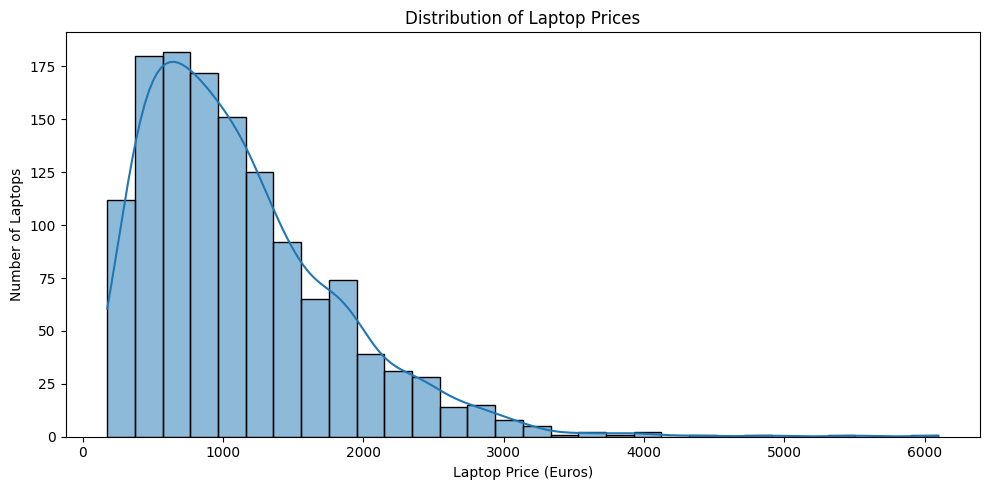

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data=df_clean,x="Price_euros",bins=30,kde=True)

plt.title("Distribution of Laptop Prices")
plt.xlabel("Laptop Price (Euros)")
plt.ylabel("Number of Laptops")

plt.tight_layout()
plt.show()

### Observation: Distribution of Laptop Prices

The histogram shows how laptop prices are spread.

- Most laptops are priced roughly between €500 and €1,500.
- The largest groups are in the lower-to-middle price range, and the count falls as price rises.
- The distribution is **right-skewed**, with a long tail towards high prices.
- A small number of laptops cost more than about €3,000, and a few reach roughly €6,000. These may be premium or high-performance models.

**Conclusion:** Prices are not normally distributed. Most laptops are moderately priced and a few are very expensive. This is a useful background for the modelling work, because those expensive laptops can be harder to predict.

# Step 6: Brand-wise Laptop Price Analysis

Average Laptop Price by Brand (Euros):


,Company,Average_Price_Euros
0,Razer,3346.14
1,LG,2099.00
2,MSI,1728.91
3,Google,1677.67
4,Microsoft,1612.31
5,Apple,1564.20
6,Huawei,1424.00
7,Samsung,1413.44
8,Toshiba,1267.81
9,Dell,1186.07


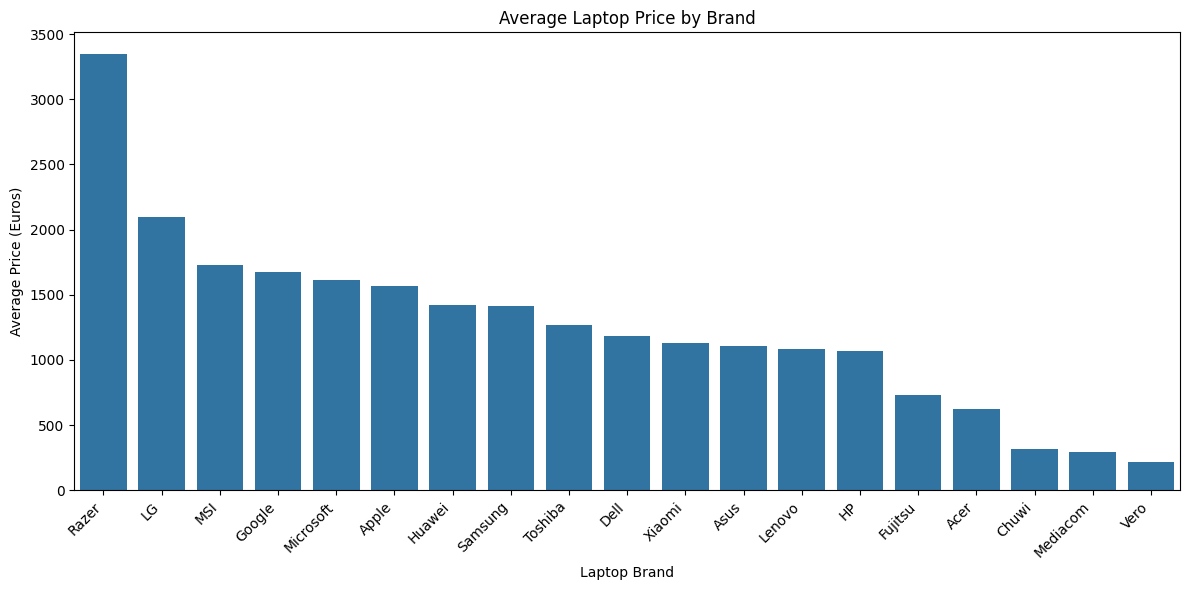

In [ ]:
# Calculate average laptop price for each company
brand_avg_price = (
    df_clean.groupby("Company")["Price_euros"].mean().sort_values(ascending=False))

# Display average prices
print("Average Laptop Price by Brand (Euros):")
display(brand_avg_price.round(2).reset_index(name="Average_Price_Euros"))

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(x=brand_avg_price.index,y=brand_avg_price.values)

plt.title("Average Laptop Price by Brand")
plt.xlabel("Laptop Brand")
plt.ylabel("Average Price (Euros)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observation: Brand-wise Average Laptop Prices

The table and bar chart compare average prices across the 19 brands in the dataset.

- **Razer** has the highest average price, about €3,346.14, followed by **LG** (€2,099.00) and **MSI** (€1,728.91).
- **Apple** averages about €1,564.20.
- **Vero** has the lowest average, about €217.42. **Mediacom** and **Chuwi** are also low.
- Average prices differ a great deal from brand to brand.

**Conclusion:** Brand may carry useful information for predicting price. These are averages over the particular models included for each brand in this dataset, and the notebook does not show how many laptops each brand has. A high average does not mean every laptop from that brand is expensive. Other specifications such as RAM, processor, storage, graphics and laptop type also play a part.

# Step 7: RAM vs Laptop Price Analysis

Average Laptop Price by RAM Capacity (Euros):



,Ram,Average_Price_Euros
0,2,254.37
1,4,574.57
2,6,615.21
3,8,1180.81
4,12,1239.44
5,16,1936.77
6,24,2206.33
7,32,3413.09
8,64,3975.00



Number of Laptops by RAM Capacity:



,Ram,Number_of_Laptops
0,2,22
1,4,375
2,6,41
3,8,619
4,12,25
5,16,200
6,24,3
7,32,17
8,64,1


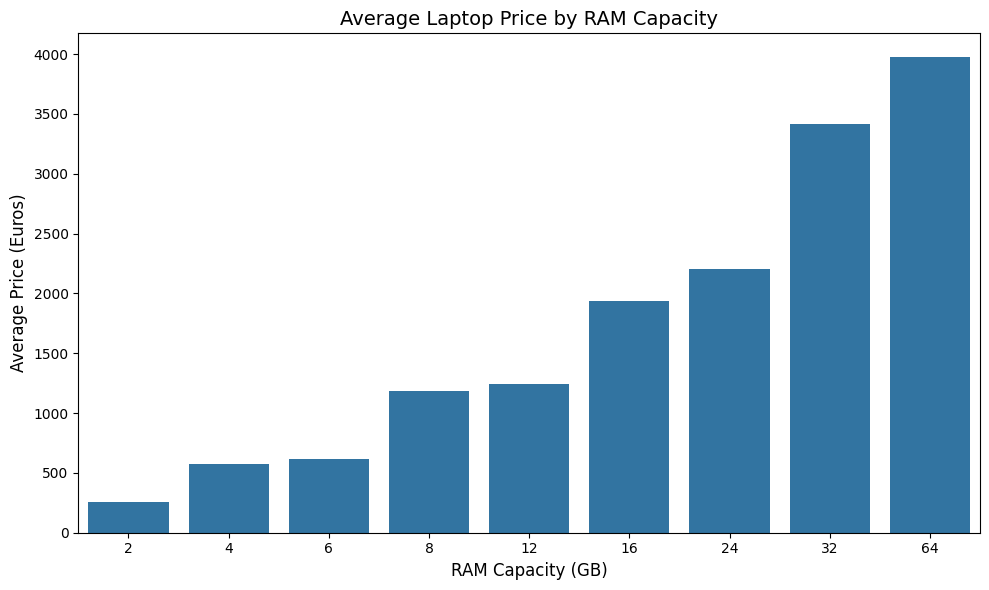


Highest Average Price:
RAM: 64 GB
Average Price: €3975.00

Lowest Average Price:
RAM: 2 GB
Average Price: €254.37


In [ ]:
# ============================================================
# STEP 7: RAM VS LAPTOP PRICE ANALYSIS
# Objective: Analyze the relationship between RAM capacity
#            and average laptop prices.
# ============================================================

# 1. Calculate the average laptop price for each RAM capacity
ram_avg_price = (df_clean.groupby("Ram")["Price_euros"].mean().sort_index())

# 2. Display the average price table
print("Average Laptop Price by RAM Capacity (Euros):\n")

display(ram_avg_price.round(2).reset_index(name="Average_Price_Euros"))

# 3. Calculate the number of laptops in each RAM category
ram_counts = df_clean["Ram"].value_counts().sort_index()

print("\nNumber of Laptops by RAM Capacity:\n")
display(ram_counts.reset_index(name="Number_of_Laptops").rename(columns={"index": "Ram"}))

# 4. Create a bar chart showing average price by RAM capacity
plt.figure(figsize=(10, 6))

sns.barplot(x=ram_avg_price.index,y=ram_avg_price.values)

# 5. Add chart title and axis labels
plt.title("Average Laptop Price by RAM Capacity", fontsize=14)
plt.xlabel("RAM Capacity (GB)", fontsize=12)
plt.ylabel("Average Price (Euros)", fontsize=12)

# 6. Improve chart readability
plt.xticks(rotation=0)
plt.tight_layout()

# 7. Display the chart
plt.show()

# 8. Print the RAM categories with the highest and lowest
#    average prices in this dataset
print("\nHighest Average Price:")
print(f"RAM: {ram_avg_price.idxmax()} GB")
print(f"Average Price: €{ram_avg_price.max():.2f}")

print("\nLowest Average Price:")
print(f"RAM: {ram_avg_price.idxmin()} GB")
print(f"Average Price: €{ram_avg_price.min():.2f}")

## RAM vs Laptop Price

This step compares average laptop price across RAM sizes and counts how many laptops fall in each RAM group.

### Observations

| RAM (GB) | Average price (€) | Laptops |
|---:|---:|---:|
| 2 | 254.37 | 22 |
| 4 | 574.57 | 375 |
| 6 | 615.21 | 41 |
| 8 | 1,180.81 | 619 |
| 12 | 1,239.44 | 25 |
| 16 | 1,936.77 | 200 |
| 24 | 2,206.33 | 3 |
| 32 | 3,413.09 | 17 |
| 64 | 3,975.00 | 1 |

### Key findings
1. Average price generally rises with RAM size.
2. 2 GB laptops have the lowest average price and the 64 GB group has the highest.
3. 8 GB is the most common size, with 619 laptops.
4. The average price jumps noticeably between 8 GB and 16 GB.
5. The 24 GB (3 laptops) and 64 GB (1 laptop) groups are very small, so their averages are not reliable.

### Conclusion
In this dataset, higher RAM is associated with higher average prices. This is an association only. It does not show that adding RAM by itself raises a laptop's price, because brand, processor, storage, graphics and type also differ between laptops. `Ram` looks like a useful input feature for a model.

# Step 8: Laptop Type vs Price Analysis

Average Laptop Price by Type (Euros):



,TypeName,Average_Price_Euros
0,Workstation,2280.36
1,Gaming,1731.38
2,Ultrabook,1548.23
3,2 in 1 Convertible,1282.40
4,Notebook,782.08
5,Netbook,636.23



Number of Laptops by Type:



,TypeName,Number_of_Laptops
0,Workstation,29
1,Gaming,205
2,Ultrabook,196
3,2 in 1 Convertible,121
4,Notebook,727
5,Netbook,25


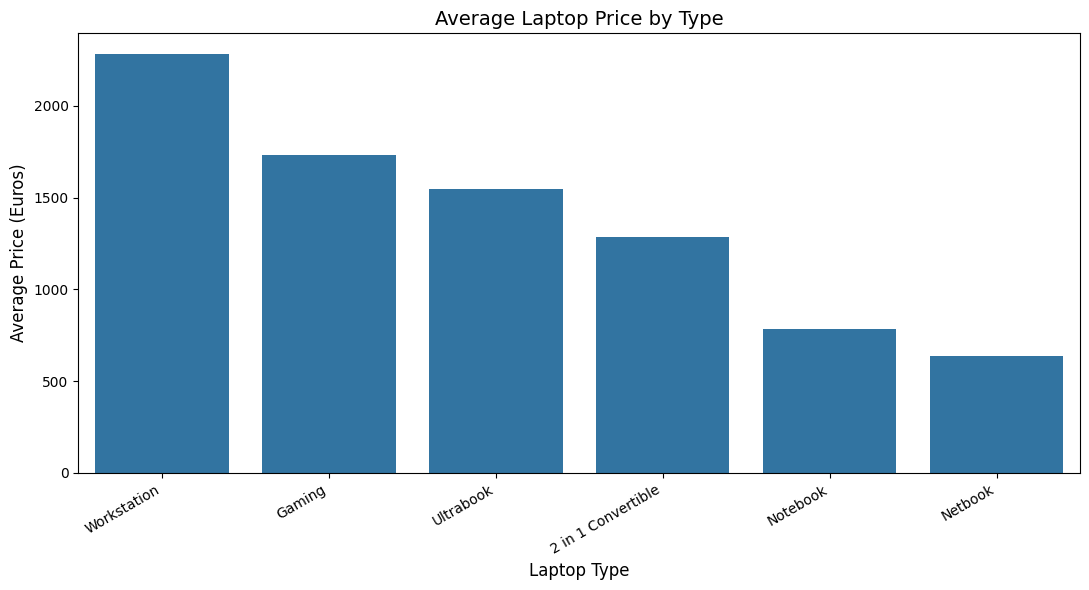


Highest Average Price:
Laptop Type: Workstation
Average Price: €2280.36

Lowest Average Price:
Laptop Type: Netbook
Average Price: €636.23

Total Laptops Analyzed: 1303


In [ ]:
# ============================================================
# STEP 8: LAPTOP TYPE VS PRICE ANALYSIS
# Objective: Compare average laptop prices across laptop types.
# ============================================================

# 1. Calculate average price for each laptop type
type_avg_price = (df_clean.groupby("TypeName")["Price_euros"].mean().sort_values(ascending=False))

# 2. Display average price for each laptop type
print("Average Laptop Price by Type (Euros):\n")

display(type_avg_price.round(2).reset_index(name="Average_Price_Euros"))

# 3. Count the number of laptops in each type
type_counts = (df_clean["TypeName"].value_counts().reindex(type_avg_price.index))

print("\nNumber of Laptops by Type:\n")

display(type_counts.rename_axis("TypeName").reset_index(name="Number_of_Laptops"))

# 4. Create a bar chart of average laptop prices
plt.figure(figsize=(11, 6))

sns.barplot(x=type_avg_price.index,y=type_avg_price.values)

# 5. Add chart title and axis labels
plt.title("Average Laptop Price by Type", fontsize=14)
plt.xlabel("Laptop Type", fontsize=12)
plt.ylabel("Average Price (Euros)", fontsize=12)

# 6. Rotate category labels for better readability
plt.xticks(rotation=30, ha="right")

# 7. Adjust layout and display the chart
plt.tight_layout()
plt.show()

# 8. Identify the laptop type with the highest average price
print("\nHighest Average Price:")
print(f"Laptop Type: {type_avg_price.idxmax()}")
print(f"Average Price: €{type_avg_price.max():.2f}")

# 9. Identify the laptop type with the lowest average price
print("\nLowest Average Price:")
print(f"Laptop Type: {type_avg_price.idxmin()}")
print(f"Average Price: €{type_avg_price.min():.2f}")

# 10. Display the number of records in each category
print("\nTotal Laptops Analyzed:", len(df_clean))

## Laptop Type vs Price

The dataset has six laptop types. We compare their average prices and group sizes.

### Observations

| Type | Average price (€) | Laptops |
|---|---:|---:|
| Workstation | 2,280.36 | 29 |
| Gaming | 1,731.38 | 205 |
| Ultrabook | 1,548.23 | 196 |
| 2 in 1 Convertible | 1,282.40 | 121 |
| Notebook | 782.08 | 727 |
| Netbook | 636.23 | 25 |

### Key findings
1. Workstations have the highest average price and Netbooks the lowest.
2. Gaming laptops and Ultrabooks average more than Notebooks and Netbooks.
3. Notebooks are the biggest group, with 727 of the 1,303 laptops.
4. Group sizes differ a lot, which should be kept in mind when reading the averages. Workstation and Netbook each have fewer than 30 laptops.

### Conclusion
Average price clearly differs between laptop types, so `TypeName` may help prediction. These are associations in this dataset. Laptop type does not decide price on its own, since brand, RAM, processor, storage and graphics also matter.

# Step 9: Screen Size vs Price Analysis

Average Laptop Price by Screen Size (Euros):



,Inches,Average_Price_Euros
0,10.1,498.32
1,11.3,1299.00
2,11.6,393.61
3,12.0,1279.90
4,12.3,1228.20
5,12.5,1583.49
6,13.0,1424.00
7,13.3,1332.32
8,13.5,1612.31
9,13.9,1637.33



Number of Laptops by Screen Size:



,Inches,Number_of_Laptops
0,10.1,4
1,11.3,1
2,11.6,33
3,12.0,6
4,12.3,5
5,12.5,39
6,13.0,2
7,13.3,164
8,13.5,6
9,13.9,6


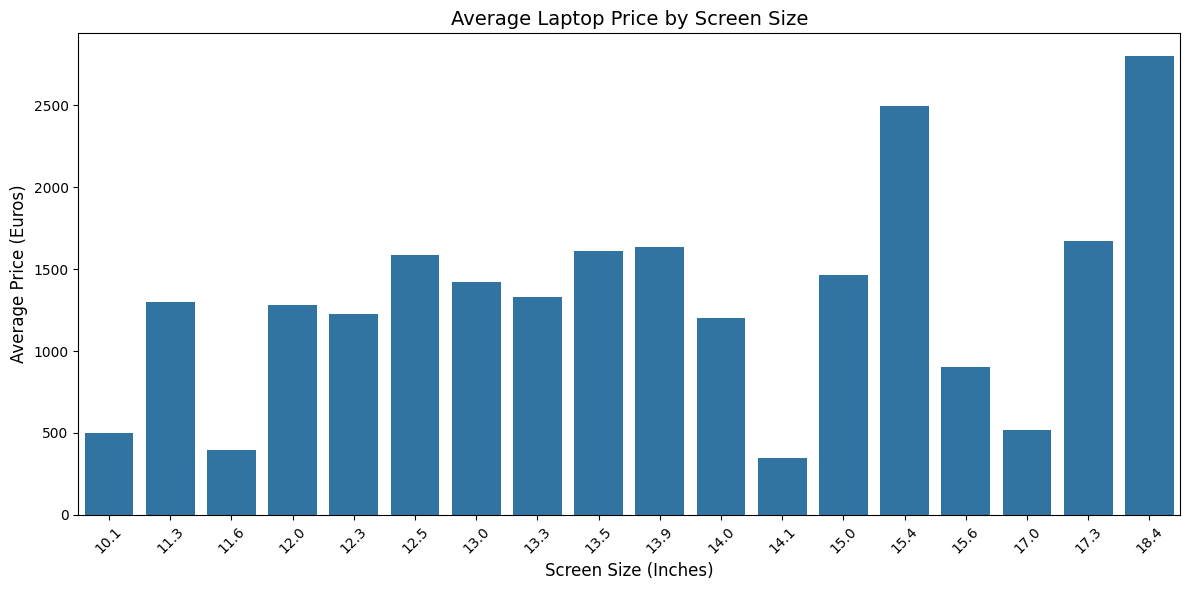

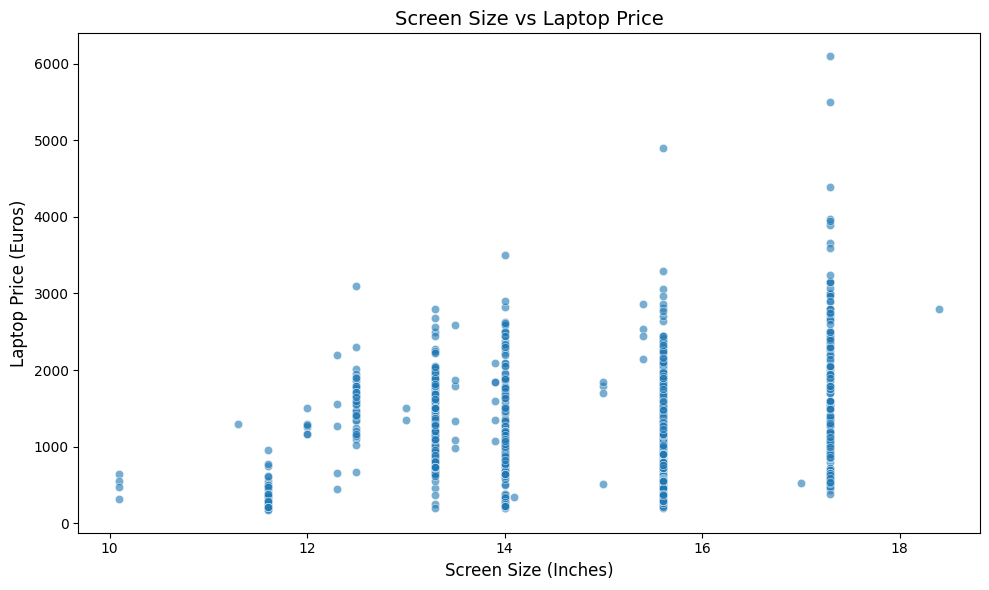


Correlation between Screen Size and Price:
0.068


In [ ]:
# ============================================================
# STEP 9: SCREEN SIZE VS LAPTOP PRICE ANALYSIS
# Objective: Analyze the relationship between screen size
#            and laptop price.
# ============================================================

# 1. Calculate average price for each screen size
screen_avg_price = (df_clean.groupby("Inches")["Price_euros"].mean().sort_index())

# 2. Display average prices by screen size
print("Average Laptop Price by Screen Size (Euros):\n")

display(screen_avg_price.round(2).reset_index(name="Average_Price_Euros"))

# 3. Count the laptops available for each screen size
screen_counts = (df_clean.groupby("Inches").size().reset_index(name="Number_of_Laptops"))
print("\nNumber of Laptops by Screen Size:\n")
display(screen_counts)

# 4. Create a bar chart of average price by screen size
plt.figure(figsize=(12, 6))

sns.barplot( x=screen_avg_price.index,y=screen_avg_price.values)

# 5. Add chart title and axis labels
plt.title("Average Laptop Price by Screen Size", fontsize=14)
plt.xlabel("Screen Size (Inches)", fontsize=12)
plt.ylabel("Average Price (Euros)", fontsize=12)

# 6. Improve chart readability
plt.xticks(rotation=45)
plt.tight_layout()

# 7. Display the chart
plt.show()

# 8. Create a scatter plot to show individual laptop prices
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_clean,x="Inches",y="Price_euros",alpha=0.6)

# 9. Add chart title and axis labels
plt.title("Screen Size vs Laptop Price", fontsize=14)
plt.xlabel("Screen Size (Inches)", fontsize=12)
plt.ylabel("Laptop Price (Euros)", fontsize=12)

# 10. Display the scatter plot
plt.tight_layout()
plt.show()

# 11. Calculate the correlation between screen size and price
correlation = df_clean["Inches"].corr(df_clean["Price_euros"])

print("\nCorrelation between Screen Size and Price:")
print(round(correlation, 3))

## Screen Size vs Laptop Price

Here we study screen size and price using average prices, a scatter plot and a correlation coefficient.

### Observations
- Screen sizes run from 10.1 to 18.4 inches.
- The 15.6-inch size is by far the most common, with 665 laptops and an average price of about €903.36.
- 14-inch (197 laptops), 13.3-inch (164) and 17.3-inch (164) are the next most common sizes.
- Average price varies between sizes. For example, 15.4-inch laptops average €2,493.85 while 15.6-inch laptops average €903.36. Several sizes have only one to six laptops, so those averages are weak evidence.
- The scatter plot shows a wide spread of prices among laptops of similar screen size.

### Correlation
The correlation between screen size and price is **0.068**. That is a very weak positive linear relationship.

### Conclusion
Screen size alone does not explain much of the variation in price. It is still kept as one of the inputs, because it may matter in combination with other features.

# Step 10: Machine Learning Data Preparation

In [ ]:
# ============================================================
# STEP 10: MACHINE LEARNING DATA PREPARATION
# Objective: Prepare features and target for Gradient Boosting.
# ============================================================

from sklearn.model_selection import train_test_split

# 1. Create a separate copy for model preparation
model_df = df_clean.copy()

# 2. Remove laptop_ID because it is an identifier,
#    not a meaningful laptop specification
model_df = model_df.drop(columns=["laptop_ID"])

# 3. Separate input features (X) and target (y)
#    X contains laptop specifications
#    y contains the price we want to predict
X = model_df.drop(columns=["Price_euros"])
y = model_df["Price_euros"]

# 4. Identify numerical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]).columns.tolist()

# 5. Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object", "category"]).columns.tolist()

# 6. Display feature information
print("Total Records:", len(model_df))
print("Total Input Features:", X.shape[1])

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Column: Price_euros")

# 7. Split the dataset into training and testing sets
#    80% for training and 20% for testing
#    random_state ensures reproducible results
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

# 8. Display the resulting dataset sizes
print("\n--- Training and Testing Data ---")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# 9. Verify that the target is not included in the input features
assert "Price_euros" not in X.columns

# 10. Verify that the identifier was removed
assert "laptop_ID" not in X.columns

print("\nData preparation completed successfully!")

# 11. Display a sample of training features
print("\nSample Training Features:")
display(X_train.head())

# 12. Display a sample of target values
print("\nSample Training Target Prices:")
display(y_train.head())

Total Records: 1303
Total Input Features: 11

Numerical Features:
['Inches', 'Ram', 'Weight']

Categorical Features:
['Company', 'Product', 'TypeName', 'ScreenResolution', 'Cpu', 'Memory', 'Gpu', 'OpSys']

Target Column: Price_euros

--- Training and Testing Data ---
X_train shape: (1042, 11)
X_test shape: (261, 11)
y_train shape: (1042,)
y_test shape: (261,)

Data preparation completed successfully!

Sample Training Features:


,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight
10,HP,250 G6,Notebook,15.6,1366x768,Intel Core i5 7200U 2.5GHz,4,500GB HDD,Intel HD Graphics 620,No OS,1.86
147,Asus,X541NA (N3350/4GB/1TB/FHD/W10),Notebook,15.6,Full HD 1920x1080,Intel Celeron Dual Core N3350 1.1GHz,4,1TB HDD,Intel HD Graphics 500,Windows 10,2.00
1287,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19
767,Dell,Inspiron 7559,Gaming,15.6,IPS Panel Touchscreen / 4K Ultra HD 3840x2160,Intel Core i7 6700HQ 2.6GHz,16,128GB SSD + 1TB HDD,Nvidia GeForce GTX 960M,Windows 10,2.72
816,Razer,Blade Stealth,Ultrabook,12.5,IPS Panel 4K Ultra HD / Touchscreen 3840x2160,Intel Core i7 7500U 2.5GHz,16,512GB SSD,Intel HD Graphics 620,Windows 10,1.29



Sample Training Target Prices:


,Price_euros
10,393.9
147,344.0
1287,764.0
767,1099.0
816,1799.0


# Step 11: Preprocessing and Gradient Boosting Model

In [ ]:
# ============================================================
# STEP 11: PREPROCESSING AND GRADIENT BOOSTING MODEL
# Objective: Preprocess laptop features and train a regression
#            model to predict laptop prices.
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]).columns.tolist()

# 2. Prepare numerical preprocessing
# Missing numerical values, if any, will be replaced by the median
numerical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))])

# 3. Prepare categorical preprocessing
# Missing categories, if any, will be replaced by the most frequent value
# OneHotEncoder converts categorical text into numerical features
categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))])

# 4. Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)])

# 5. Create the Gradient Boosting Regressor
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42)

# 6. Build one pipeline for preprocessing and model training
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", gradient_boosting_model) ])

# 7. Train the complete pipeline using training data only
model_pipeline.fit(X_train, y_train)

print("Gradient Boosting model training completed successfully!")

# 8. Predict laptop prices for the unseen test data
y_pred = model_pipeline.predict(X_test)

# 9. Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Gradient Boosting Model Evaluation ---")
print(f"Mean Absolute Error (MAE): €{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): €{rmse:.2f}")
print(f"R² Score: {r2:.4f}")

# 10. Compare actual and predicted prices for sample test records
comparison = X_test[["Company", "Product"]].copy()
comparison["Actual_Price_Euros"] = y_test
comparison["Predicted_Price_Euros"] = np.round(y_pred, 2)
comparison["Absolute_Error_Euros"] = np.round(
    np.abs(y_test.to_numpy() - y_pred), 2)

print("\n--- Actual vs Predicted Prices (First 10 Test Records) ---")
display(comparison.head(10))

Gradient Boosting model training completed successfully!

--- Gradient Boosting Model Evaluation ---
Mean Absolute Error (MAE): €200.30
Root Mean Squared Error (RMSE): €290.21
R² Score: 0.8342

--- Actual vs Predicted Prices (First 10 Test Records) ---


,Company,Product,Actual_Price_Euros,Predicted_Price_Euros,Absolute_Error_Euros
479,Toshiba,Portege X30-D-10J,1672.00,1230.71,441.29
1022,HP,Spectre 13-V100nv,1149.00,1223.99,74.99
298,Lenovo,IdeaPad 310-15ABR,499.00,563.26,64.26
1265,Lenovo,IdeaPad Y700-15ISK,899.00,777.41,121.59
774,HP,EliteBook 820,1244.00,1002.78,241.22
115,HP,Spectre x360,1398.99,1442.40,43.41
582,HP,ProBook 430,719.00,716.83,2.17
527,Lenovo,IdeaPad 320-15ISK,459.00,727.09,268.09
380,HP,Omen 17-w212nv,1191.00,1235.85,44.85
101,HP,15-bw000nv (E2-9000e/4GB/500GB/Radeon,349.00,570.49,221.49


## Gradient Boosting: Training and Evaluation

A Gradient Boosting Regressor is trained to predict laptop prices from the other specifications.

### Data preparation
- `laptop_ID` is dropped because it is an identifier, not a laptop specification.
- `Price_euros` is the target (`y`); the remaining **11 columns** are the inputs (`X`).
- Numeric inputs: `Inches`, `Ram`, `Weight`.
- Categorical inputs: `Company`, `Product`, `TypeName`, `ScreenResolution`, `Cpu`, `Memory`, `Gpu`, `OpSys`.
- The data is split **80% / 20%** with `random_state=42`: 1,042 training rows and 261 test rows.

### Preprocessing
- Numeric columns: median imputation (the data has no missing values, so this changes nothing here, but it keeps the pipeline safe).
- Categorical columns: most-frequent imputation, then one-hot encoding with `handle_unknown="ignore"`.
- Preprocessing and the model are combined in one scikit-learn `Pipeline` and fitted on the training data only, which avoids leaking test information into preprocessing.

> Note: `Product` has 618 distinct names, so one-hot encoding creates a very large number of sparse columns for it. The notebook does not test what happens if `Product` is removed.

### The algorithm
Gradient Boosting builds decision trees one after another, and each new tree tries to correct the errors left by the trees before it. Settings used: 100 estimators, learning rate 0.1, maximum depth 3, `random_state=42`.

### Test-set results

| Metric | Result | Meaning |
|---|---:|---|
| MAE | €200.30 | On average, predictions are about €200.30 away from the actual price. |
| RMSE | €290.21 | Like MAE but penalises large errors more heavily. |
| R² | 0.8342 | About 83.42% of the variation in test prices is explained, compared with simply predicting the mean. |

### Actual vs predicted examples
The first ten test laptops show that accuracy varies. A laptop priced at €719.00 was predicted at €716.83 (error €2.17), while one priced at €1,672.00 was predicted at €1,230.71 (error €441.29). A few examples cannot describe the model, which is why the full test set is used for evaluation.

### Conclusion
Gradient Boosting explains a large share of price variation (R² = 0.8342), but errors remain, so the predictions are estimates and not exact prices. Later steps compare it with Random Forest and Linear Regression.

# Step 12: Actual vs Predicted Price Visualisation

Actual vs Predicted Laptop Prices (First 10 Records):



,Actual_Price,Predicted_Price,Absolute_Error
0,1672.00,1230.71,441.29
1,1149.00,1223.99,74.99
2,499.00,563.26,64.26
3,899.00,777.41,121.59
4,1244.00,1002.78,241.22
5,1398.99,1442.40,43.41
6,719.00,716.83,2.17
7,459.00,727.09,268.09
8,1191.00,1235.85,44.85
9,349.00,570.49,221.49



Prediction Error Summary:



,Absolute_Error
count,261.00
mean,200.30
std,210.40
min,0.31
25%,65.24
50%,155.65
75%,292.37
max,1737.75


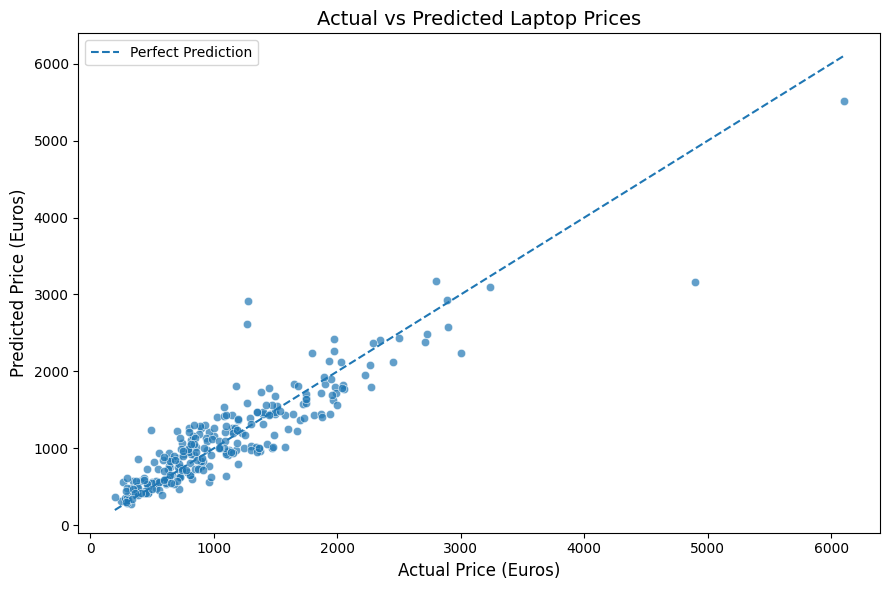

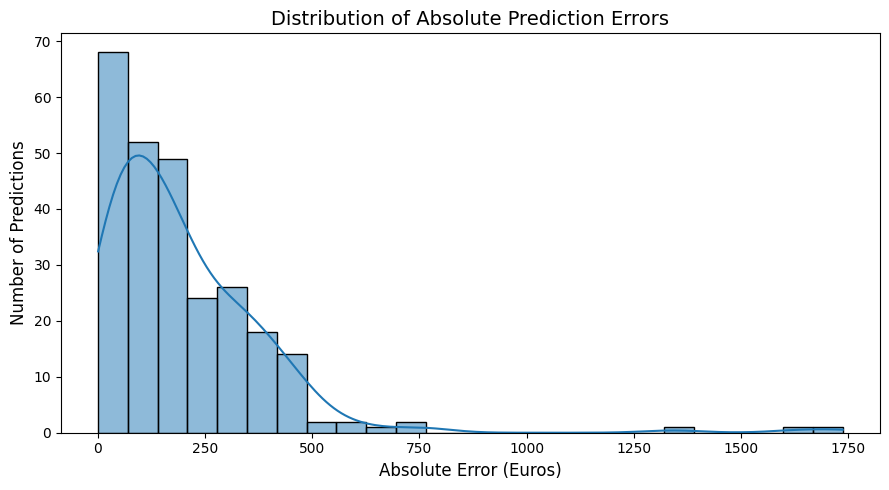


Total Test Predictions: 261
Mean Absolute Error: €200.30
Maximum Absolute Error: €1737.75


In [ ]:
# ============================================================
# STEP 12: ACTUAL VS PREDICTED PRICE VISUALIZATION
# Objective: Visualize and compare actual and predicted prices.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Create a DataFrame containing actual and predicted prices
results_df = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": y_pred})

# 2. Calculate the absolute prediction error
results_df["Absolute_Error"] = np.abs(
    results_df["Actual_Price"] - results_df["Predicted_Price"])

# 3. Display the first 10 comparisons
print("Actual vs Predicted Laptop Prices (First 10 Records):\n")
display(results_df.head(10).round(2))

# 4. Display summary statistics of prediction errors
print("\nPrediction Error Summary:\n")
display(results_df["Absolute_Error"].describe().round(2))

# 5. Create a scatter plot comparing actual and predicted prices
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=results_df,x="Actual_Price", y="Predicted_Price",alpha=0.7)

# 6. Draw a reference line representing perfect predictions
# Points close to this line indicate more accurate predictions
min_price = min(
    results_df["Actual_Price"].min(),
    results_df["Predicted_Price"].min())

max_price = max(
    results_df["Actual_Price"].max(),
    results_df["Predicted_Price"].max())

plt.plot([min_price, max_price],[min_price, max_price],linestyle="--",label="Perfect Prediction")

# 7. Add chart title, axis labels, and legend
plt.title("Actual vs Predicted Laptop Prices", fontsize=14)
plt.xlabel("Actual Price (Euros)", fontsize=12)
plt.ylabel("Predicted Price (Euros)", fontsize=12)
plt.legend()

# 8. Improve layout and display the graph
plt.tight_layout()
plt.show()

# 9. Plot the distribution of absolute prediction errors
plt.figure(figsize=(9, 5))

sns.histplot(results_df["Absolute_Error"],bins=25,kde=True)

# 10. Add labels and display the error distribution
plt.title("Distribution of Absolute Prediction Errors", fontsize=14)
plt.xlabel("Absolute Error (Euros)", fontsize=12)
plt.ylabel("Number of Predictions", fontsize=12)

plt.tight_layout()
plt.show()

# 11. Display the number of test predictions evaluated
print("\nTotal Test Predictions:", len(results_df))
print(f"Mean Absolute Error: €{results_df['Absolute_Error'].mean():.2f}")
print(f"Maximum Absolute Error: €{results_df['Absolute_Error'].max():.2f}")

## Actual vs Predicted Laptop Prices

These plots compare the Gradient Boosting predictions with the actual prices on the 261 test laptops.

### Actual vs predicted scatter plot
Points on the dashed diagonal would be perfect predictions.

- Many points sit fairly close to the line, especially in the lower and middle price ranges.
- Some points are far from the line.
- For some expensive laptops the model predicts a price well below the actual price.

### Distribution of absolute errors

| Statistic | Value |
|---|---:|
| Mean absolute error | €200.30 |
| Median absolute error | €155.65 |
| 25th – 75th percentile | €65.24 – €292.37 |
| Maximum absolute error | €1,737.75 |

Most errors are fairly small, and a smaller number are much larger.

### Interpretation
The model predicts many prices reasonably well but is not equally reliable for every laptop. Its largest errors appear for some high-priced models. Examining those laptops, comparing other algorithms and tuning parameters are sensible next steps.

# Step 13: Correlation Heatmap

Correlation Matrix:



,Inches,Ram,Weight,Price_euros
Inches,1.000,0.238,0.828,0.068
Ram,0.238,1.000,0.384,0.743
Weight,0.828,0.384,1.000,0.210
Price_euros,0.068,0.743,0.210,1.000


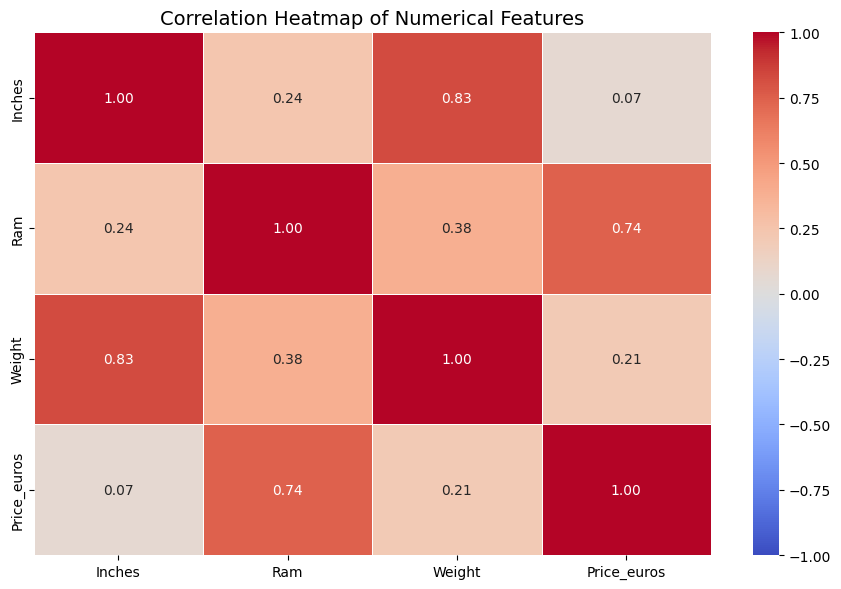


Correlation with Laptop Price:



,Price_euros
Ram,0.743
Weight,0.210
Inches,0.068


In [ ]:
# STEP 13: CORRELATION HEATMAP

import matplotlib.pyplot as plt
import seaborn as sns

numerical_df = df_clean.select_dtypes(include=["int64", "float64"]).drop(columns=["laptop_ID"], errors="ignore")
correlation_matrix = numerical_df.corr()

print("Correlation Matrix:\n")
display(correlation_matrix.round(3))

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14)
plt.tight_layout()
plt.show()

print("\nCorrelation with Laptop Price:\n")
price_correlation = correlation_matrix["Price_euros"].drop("Price_euros").sort_values(ascending=False)
display(price_correlation.round(3))

## Correlation Heatmap

The heatmap shows linear correlations between the three numeric inputs (`Inches`, `Ram`, `Weight`) and `Price_euros`.

| Pair | Correlation |
|---|---:|
| RAM and Price | 0.743 |
| Weight and Price | 0.210 |
| Screen size and Price | 0.068 |
| Screen size and Weight | 0.828 |
| RAM and Weight | 0.384 |
| Screen size and RAM | 0.238 |

### Key findings
1. RAM has the strongest linear correlation with price (0.743) among the three numeric inputs.
2. Screen size has almost no linear correlation with price (0.068).
3. Screen size and weight are strongly correlated with each other (0.828), so larger screens tend to go with heavier laptops in this data.
4. Correlation measures linear association only. It does not prove that one variable causes another.
5. A weak correlation does not make a feature useless for a model, since the relationship may be non-linear or depend on other features.

### Conclusion
RAM appears to be an informative numeric feature. The heatmap covers only numeric columns, so it says nothing about brand, processor, graphics or laptop type.

# Step 14: Confusion Matrix (Gradient Boosting Predictions Grouped into Categories)

Truth Table / Confusion Matrix:


,Low,Medium,High
Low,58,19,0
Medium,12,109,10
High,0,12,41


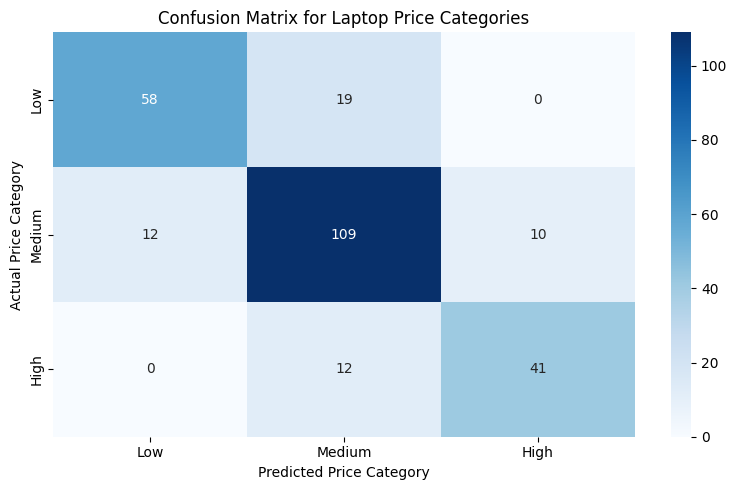


Classification Report:
              precision    recall  f1-score   support

         Low       0.83      0.75      0.79        77
      Medium       0.78      0.83      0.80       131
        High       0.80      0.77      0.79        53

    accuracy                           0.80       261
   macro avg       0.80      0.79      0.79       261
weighted avg       0.80      0.80      0.80       261



In [ ]:
# CONFUSION MATRIX

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Convert actual and predicted prices into price categories
price_bins = [0, 700, 1500, float("inf")]
price_labels = ["Low", "Medium", "High"]

actual_categories = pd.cut(y_test, bins=price_bins, labels=price_labels)
predicted_categories = pd.cut(pd.Series(y_pred, index=y_test.index), bins=price_bins, labels=price_labels)

# Create and display the confusion matrix
cm = confusion_matrix(actual_categories, predicted_categories, labels=price_labels)
cm_df = pd.DataFrame(cm, index=price_labels, columns=price_labels)

print("Truth Table / Confusion Matrix:")
display(cm_df)

# Visualize the confusion matrix
plt.figure(figsize=(8, 5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix for Laptop Price Categories")
plt.xlabel("Predicted Price Category")
plt.ylabel("Actual Price Category")
plt.tight_layout()
plt.show()

# Display classification performance
print("\nClassification Report:")
print(classification_report(actual_categories, predicted_categories, labels=price_labels, zero_division=0))

## Confusion Matrix for Price Categories (from Gradient Boosting)

**What this analysis is.** The actual test prices and the Gradient Boosting *regression* predictions are both sorted into Low, Medium and High using the same thresholds (€700 and €1,500). The confusion matrix then shows how often the predicted category matches the actual one. This is an extra view of the regression model. It is **not** the Logistic Regression classifier, which is evaluated separately in Step 18.

### Confusion matrix

| Actual \ Predicted | Low | Medium | High |
|---|---:|---:|---:|
| Low | 58 | 19 | 0 |
| Medium | 12 | 109 | 10 |
| High | 0 | 12 | 41 |

### Observations
- **Low:** of 77 actual Low laptops, 58 were placed in Low and 19 in Medium.
- **Medium:** of 131 actual Medium laptops, 109 were placed in Medium, 12 in Low and 10 in High.
- **High:** of 53 actual High laptops, 41 were placed in High and 12 in Medium.
- No Low laptop was predicted as High, and no High laptop was predicted as Low.

### Classification report

| Metric | Low | Medium | High |
|---|---:|---:|---:|
| Precision | 0.83 | 0.78 | 0.80 |
| Recall | 0.75 | 0.83 | 0.77 |
| F1-score | 0.79 | 0.80 | 0.79 |

Overall accuracy is about **0.80** (208 of 261 correct).

### Conclusion
Most laptops land in the right category, and the mistakes are between neighbouring categories. Because this is an additional analysis of a regression model, MAE, RMSE and R² remain its main metrics.

> The test-set category counts here (77 / 131 / 53) differ from those used for Logistic Regression (84 / 116 / 61), because that classifier uses its own stratified split. The two sets of category results should therefore not be compared directly.

# Step 15: Random Forest vs Gradient Boosting

Random Forest vs Gradient Boosting:



,MAE (€),RMSE (€),R2 Score
Model,,,
Random Forest,184.0099,309.8166,0.8110
Gradient Boosting,200.2995,290.2075,0.8342


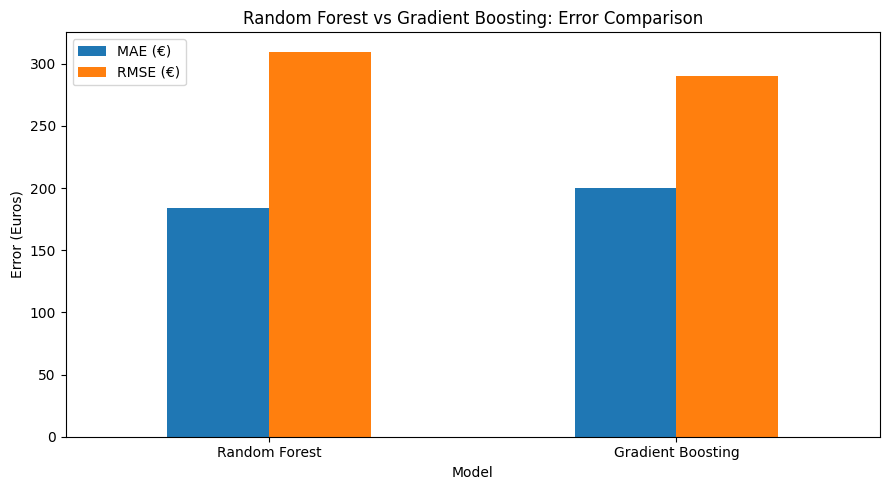

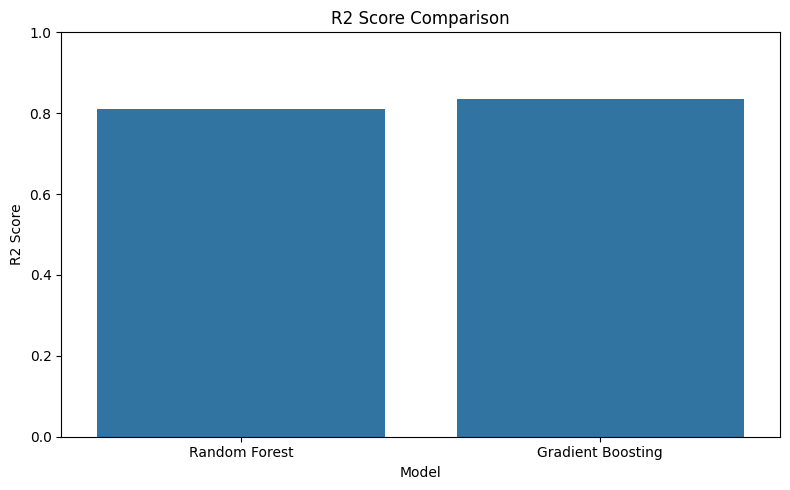

Model with Lower MAE: Random Forest
Random Forest: MAE = €184.01, RMSE = €309.82, R2 = 0.8110
Gradient Boosting: MAE = €200.30, RMSE = €290.21, R2 = 0.8342


In [ ]:
# STEP 15: RANDOM FOREST VS GRADIENT BOOSTING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create both models
rf_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])
gb_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))])

# Train both models using the same training data
rf_pipeline.fit(X_train, y_train)
gb_pipeline.fit(X_train, y_train)

# Predict prices on the same test dataset
rf_pred = rf_pipeline.predict(X_test)
gb_pred = gb_pipeline.predict(X_test)

# Calculate evaluation metrics
comparison_df = pd.DataFrame([
    {"Model": "Random Forest", "MAE (€)": mean_absolute_error(y_test, rf_pred), "RMSE (€)": np.sqrt(mean_squared_error(y_test, rf_pred)), "R2 Score": r2_score(y_test, rf_pred)},
    {"Model": "Gradient Boosting", "MAE (€)": mean_absolute_error(y_test, gb_pred), "RMSE (€)": np.sqrt(mean_squared_error(y_test, gb_pred)), "R2 Score": r2_score(y_test, gb_pred)}
]).set_index("Model")

# Display comparison table
print("Random Forest vs Gradient Boosting:\n")
display(comparison_df.round(4))

# Plot MAE and RMSE comparison
comparison_df[["MAE (€)", "RMSE (€)"]].plot(kind="bar", figsize=(9, 5))
plt.title("Random Forest vs Gradient Boosting: Error Comparison")
plt.ylabel("Error (Euros)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Plot R2 score comparison
plt.figure(figsize=(8, 5))
sns.barplot(x=comparison_df.index, y=comparison_df["R2 Score"])
plt.title("R2 Score Comparison")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

# Identify the model with lower MAE
print("Model with Lower MAE:", comparison_df["MAE (€)"].idxmin())

# Display final metrics
for name, row in comparison_df.iterrows():
    print(f"{name}: MAE = €{row['MAE (€)']:.2f}, RMSE = €{row['RMSE (€)']:.2f}, R2 = {row['R2 Score']:.4f}")

## Random Forest vs Gradient Boosting

A Random Forest Regressor (100 trees, `random_state=42`) and the Gradient Boosting Regressor are trained on the same training data and evaluated on the same test data.

| Model | MAE (€) | RMSE (€) | R² |
|---|---:|---:|---:|
| Random Forest | 184.01 | 309.82 | 0.8110 |
| Gradient Boosting | 200.30 | 290.21 | 0.8342 |

### Observations
- Random Forest has the lower **MAE** (€184.01), so its average absolute error is smaller.
- Gradient Boosting has the lower **RMSE** (€290.21) and the higher **R²** (0.8342). RMSE gives extra weight to large errors, so this suggests Random Forest made some larger mistakes.
- Neither model wins on every metric.

### Conclusion
Between these two models, the better choice depends on the metric that matters most. Gradient Boosting is preferable if large errors are a concern. Random Forest is preferable if the typical error matters most. Linear Regression is added in the next step for a fuller comparison.

# Step 16: Linear Regression Model

In [ ]:
# STEP 16: LINEAR REGRESSION
from sklearn.linear_model import LinearRegression
# Create and train the model using existing preprocessing
lr_pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", LinearRegression())])
lr_pipeline.fit(X_train, y_train)

# Predict laptop prices
lr_pred = lr_pipeline.predict(X_test)

# Evaluate model performance
lr_results = pd.DataFrame([{
    "Model": "Linear Regression",
    "MAE (€)": mean_absolute_error(y_test, lr_pred),
    "RMSE (€)": np.sqrt(mean_squared_error(y_test, lr_pred)),
    "R2 Score": r2_score(y_test, lr_pred)
}]).set_index("Model")

# Display results
display(lr_results.round(4))

,MAE (€),RMSE (€),R2 Score
Model,,,
Linear Regression,190.0119,282.9067,0.8424


## Linear Regression

A Linear Regression model is trained with the same preprocessing pipeline and the same train-test split.

| Metric | Value |
|---|---:|
| MAE | €190.01 |
| RMSE | €282.91 |
| R² | 0.8424 |

### Observations
- **MAE (€190.01):** predictions are about €190 away from the actual price on average.
- **RMSE (€282.91):** large errors are weighted more heavily than in MAE.
- **R² (0.8424):** about 84.24% of the variation in test prices is explained.

### Conclusion
Linear Regression has a higher R² than Random Forest (0.8110) and Gradient Boosting (0.8342), and it also has the lowest RMSE of the three models. Random Forest still has the lowest MAE (€184.01). A simple model competes well here, so more complex models are not automatically better.

# Step 17: Final Regression Model Comparison

In [ ]:
# STEP 17: FINAL MODEL COMPARISON

# Compare all three models using the same evaluation metrics
comparison_df = pd.DataFrame([
    {"Model": "Linear Regression", "MAE (€)": mean_absolute_error(y_test, lr_pred), "RMSE (€)":
     np.sqrt(mean_squared_error(y_test, lr_pred)), "R2 Score": r2_score(y_test, lr_pred)},
    {"Model": "Random Forest", "MAE (€)": mean_absolute_error(y_test, rf_pred), "RMSE (€)":
     np.sqrt(mean_squared_error(y_test, rf_pred)), "R2 Score": r2_score(y_test, rf_pred)},
    {"Model": "Gradient Boosting", "MAE (€)": mean_absolute_error(y_test, gb_pred), "RMSE (€)":
     np.sqrt(mean_squared_error(y_test, gb_pred)), "R2 Score": r2_score(y_test, gb_pred)}
]).set_index("Model")

# Display comparison
display(comparison_df.round(4))

# Identify the best model for each metric
print("Lowest MAE:", comparison_df["MAE (€)"].idxmin())
print("Lowest RMSE:", comparison_df["RMSE (€)"].idxmin())
print("Highest R2 Score:", comparison_df["R2 Score"].idxmax())

,MAE (€),RMSE (€),R2 Score
Model,,,
Linear Regression,190.0119,282.9067,0.8424
Random Forest,184.0099,309.8166,0.8110
Gradient Boosting,200.2995,290.2075,0.8342


Lowest MAE: Random Forest
Lowest RMSE: Linear Regression
Highest R2 Score: Linear Regression


## Comparison of Regression Models

All three regression models are compared on the same test set.

| Model | MAE (€) | RMSE (€) | R² |
|---|---:|---:|---:|
| Linear Regression | 190.01 | 282.91 | 0.8424 |
| Random Forest | 184.01 | 309.82 | 0.8110 |
| Gradient Boosting | 200.30 | 290.21 | 0.8342 |

### Observations
- **Lowest MAE:** Random Forest (€184.01).
- **Lowest RMSE:** Linear Regression (€282.91).
- **Highest R²:** Linear Regression (0.8424).
- The differences between the models are fairly small, and they come from a single train-test split.

### Conclusion
On RMSE and R², Linear Regression is the strongest of the three. On MAE, Random Forest is the strongest. The results show that a simple model can perform competitively on this dataset. The final choice depends on which metric matters most for the intended use.

# Step 18: Logistic Regression (Price-Category Classification)

In [ ]:
# STEP 18: LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
# Create price categories
y_class = pd.cut(df_clean["Price_euros"], bins=[0, 700, 1500, np.inf], labels=["Low", "Medium", "High"])

# Prepare classification dataset
X_class = df_clean.drop(columns=["laptop_ID", "Price_euros"])
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(X_class, y_class, test_size=0.20, random_state=42, stratify=y_class)

# Create and train Logistic Regression model using existing preprocessing
logistic_model = Pipeline([("preprocessor", clone(preprocessor)), ("model", LogisticRegression(max_iter=2000))])
logistic_model.fit(X_train_cls, y_train_cls)

# Predict price categories
y_class_pred = logistic_model.predict(X_test_cls)

# Evaluate classification performance
from sklearn.metrics import accuracy_score, classification_report
print("Logistic Regression Accuracy:", round(accuracy_score(y_test_cls, y_class_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test_cls, y_class_pred))

Logistic Regression Accuracy: 0.8506

Classification Report:

              precision    recall  f1-score   support

        High       0.78      0.75      0.77        61
         Low       0.93      0.94      0.93        84
      Medium       0.83      0.84      0.83       116

    accuracy                           0.85       261
   macro avg       0.85      0.84      0.84       261
weighted avg       0.85      0.85      0.85       261



## Logistic Regression for Price Categories

Logistic Regression is used to classify laptops into three price categories. Unlike the regression models, it predicts a category, not an exact price.

- **Low:** Price ≤ €700
- **Medium:** €700 < Price ≤ €1500
- **High:** Price > €1500

The data is split 80:20 with `random_state=42`, using a **stratified** split so each category keeps a similar share in the training and test sets. The same preprocessing pipeline is reused. The test set has 261 laptops.

### Results

Accuracy: **0.8506 (85.06%)**

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| High | 0.78 | 0.75 | 0.77 | 61 |
| Low | 0.93 | 0.94 | 0.93 | 84 |
| Medium | 0.83 | 0.84 | 0.83 | 116 |
| **Macro average** | 0.85 | 0.84 | 0.84 | 261 |
| **Weighted average** | 0.85 | 0.85 | 0.85 | 261 |

### Observations
- Low-priced laptops are classified best (F1 = 0.93).
- Medium-priced laptops follow (F1 = 0.83).
- High-priced laptops are hardest (F1 = 0.77).

### Conclusion
Logistic Regression performs well on this three-class problem, especially for Low and Medium laptops. It complements the regression models by giving a price category instead of an exact price.

# Step 19: ROC Curve and ROC-AUC

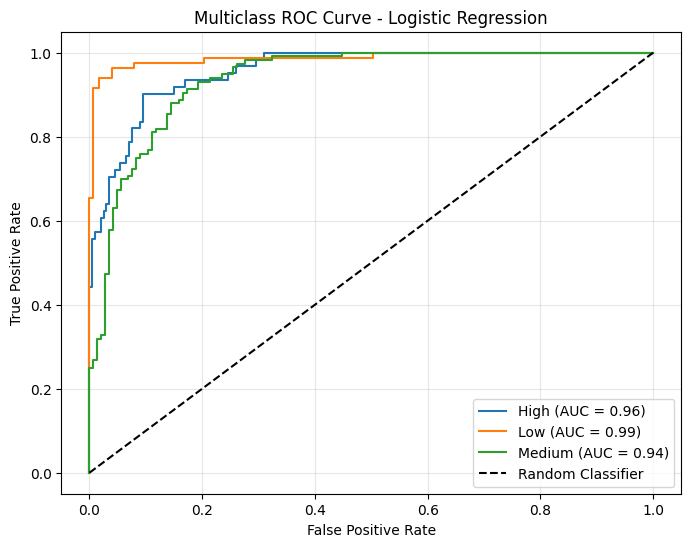

Macro ROC-AUC: 0.9606
Weighted ROC-AUC: 0.9581


In [ ]:
#  ROC CURVE AND ROC-AUC
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
# Get predicted probabilities for each price category
y_class_proba = logistic_model.predict_proba(X_test_cls)

# Calculate ROC curve and AUC for each class
y_test_bin = label_binarize(y_test_cls, classes=logistic_model.named_steps["model"].classes_)
plt.figure(figsize=(8, 6))

for i, category in enumerate(logistic_model.named_steps["model"].classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_class_proba[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{category} (AUC = {class_auc:.2f})")

# Plot random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calculate overall multiclass ROC-AUC
print("Macro ROC-AUC:", round(roc_auc_score(y_test_bin, y_class_proba, average="macro"), 4))
print("Weighted ROC-AUC:", round(roc_auc_score(y_test_bin, y_class_proba, average="weighted"), 4))

## Multiclass ROC Curve and ROC-AUC

A ROC curve is drawn for each price category in a one-vs-rest way, using the predicted probabilities from the Logistic Regression model. The area under each curve (AUC) shows how well the model separates that category from the others.

### Per-category AUC

| Category | ROC-AUC |
|---|---:|
| High | 0.96 |
| Low | 0.99 |
| Medium | 0.94 |

### Overall ROC-AUC

| Average | Score | Meaning |
|---|---:|---|
| Macro | 0.9606 | Simple average of the three category AUCs; each category counts equally. |
| Weighted | 0.9581 | Average weighted by the number of test samples in each category. |

### Observations
- The curves sit well above the diagonal "random classifier" line.
- Low is separated best (AUC 0.99). Medium is the lowest (AUC 0.94), though still high.
- ROC-AUC looks at how well categories are separated across all probability thresholds, so it adds to accuracy, precision, recall and F1-score.

### Conclusion
The Logistic Regression model separates the three price categories well on this test set. As with all test-set numbers, this is an estimate for this dataset and split, not a guarantee for new data.

# 20. Interpretation of Results

## 20.1 Exploratory data analysis
The main findings were:

- Prices are right-skewed: most laptops are in the lower-to-middle range, with a small number of expensive ones.
- Razer has the highest average price among the brands and Vero the lowest.
- RAM is positively correlated with price (0.743).
- Workstation and Gaming laptops have higher average prices than Notebook and Netbook models.
- Screen size has only a very weak linear correlation with price (0.068).

Prices appear to be associated with several specifications at once, not a single feature. These are associations within this dataset, and they do not prove causation.

## 20.2 Regression models

| Model | MAE (€) | RMSE (€) | R² |
|---|---:|---:|---:|
| Linear Regression | 190.01 | 282.91 | 0.8424 |
| Random Forest | 184.01 | 309.82 | 0.8110 |
| Gradient Boosting | 200.30 | 290.21 | 0.8342 |

- **Linear Regression** has the lowest RMSE and the highest R².
- **Random Forest** has the lowest MAE, but its higher RMSE shows that some large errors affected it more.
- **Gradient Boosting** is competitive (R² = 0.8342) but did not come first on any metric.

## 20.3 Logistic Regression
Logistic Regression reached an accuracy of 0.8506. Its F1-scores were 0.93 (Low), 0.83 (Medium) and 0.77 (High), so Low-priced laptops were classified more reliably than High-priced ones on this test set.

## 20.4 ROC-AUC
Per-category AUCs were 0.99 (Low), 0.96 (High) and 0.94 (Medium). The macro ROC-AUC was 0.9606 and the weighted ROC-AUC was 0.9581, which shows that the model separates the categories well.

---

# 21. Final Model Selection

The right model depends on the task.

## 21.1 Price prediction (regression)
**Linear Regression** is selected as the preferred model for this project, because it has the lowest RMSE (€282.91) and the highest R² (0.8424) and is also the simplest of the three models.

Trade-off: Random Forest has a lower MAE (€184.01), so it may be preferred if the average absolute error is the main goal. The gaps between the models are small and come from a single train-test split, so this is a preference based on the current results and not a claim that Linear Regression is best for all data.

## 21.2 Price-category prediction (classification)
**Logistic Regression** is the classification model. It reached 0.8506 accuracy and a macro ROC-AUC of 0.9606, and it provides class probabilities.

Regression and classification models answer different questions and are measured with different metrics, so they should not be compared with each other directly.

---

# 22. Practical Applications

The models could potentially support price estimation from specifications, shopping assistance, price comparison, market analysis and decision support. These are possible uses only. They would need to be checked against current market data.

---

# 23. Limitations

- **Dataset size:** 1,303 records may not cover every model, brand, market or price range.
- **Changing prices:** prices move with new releases, discounts, inflation and demand, so a model trained on historical data may not match current prices.
- **Evaluation method:** results come from a single train-test split and may change with a different split. Cross-validation was not performed.
- **Prediction errors:** all regression models have non-zero errors, so predictions are estimates, not guaranteed prices.
- **Fixed thresholds:** the categories use fixed cut-offs of €700 and €1,500. Other thresholds could change the classification results.
- **No external validation:** the models were not tested on a separate dataset of new laptops or current prices.
- **Product names as a feature:** `Product` (618 distinct names) was used as a categorical input. The notebook did not test its effect, so its influence on the results is unknown.
- **No tuning:** the models were run with fixed settings, with no hyperparameter search.

---

# 24. Future Improvements

*These are proposals. None of them was carried out in this notebook.*

1. **Collect updated data** with current prices and specifications.
2. **Apply cross-validation** to check how stable the results are.
3. **Tune hyperparameters** with Grid Search or Randomised Search.
4. **Improve feature engineering**, for example processor details, storage size and type, GPU category and display resolution, taking care to avoid information leakage.
5. **Analyse feature importance** with suitable explainability techniques, remembering that one-hot encoding splits a single feature across many columns.
6. **Test on external data** to see how well the models generalise.
7. **Build a web application** where a user enters specifications and receives an estimated price, a predicted category and a note about the prediction's limits.

---

# 25. Final Conclusion

This project explored laptop prices through exploratory data analysis and several machine learning models. The EDA looked at the price distribution, brand averages, RAM, laptop type, screen size and correlations.

Three regression models were evaluated. Linear Regression had the lowest RMSE (€282.91) and the highest R² (0.8424), and Random Forest had the lowest MAE (€184.01). Linear Regression is therefore the preferred regression model on RMSE and R², with Random Forest a strong alternative when MAE is the priority.

Logistic Regression classified laptops into Low, Medium and High price categories with an accuracy of 0.8506, a macro ROC-AUC of 0.9606 and a weighted ROC-AUC of 0.9581.

The results are promising, but they are estimates from one dataset and one split. Updated data, cross-validation, hyperparameter tuning and external validation would be needed before the models are used for real-world price estimation.